### Notebook #3: Multi-Class Classification using Salary Tiers

This is the second part of our project. Here, we are doing multi-class classification with 5 different NBA salary tiers a player's season can fall into. We are using the same feature matrix as binary classification (per-game box-score statistics, demographics, and position). Here, we are being more rigid with player classification.

The 5 classes, defined by within-season percentile ranking of salary:

| Tier | Label | Percentile | Description |
|------|-------|------------|-------------|
| 1 | Minimum | Bottom 40% | Rookie contract or end-of-bench/deep rotation players (9th-10th+ man on teams) |
| 2 | Role Player | 40th–70th | Standard rotation contracts (think players populating bench rotations and lower-end starters) |
| 3 | Starter | 70th–90th | Quality starter contracts |
| 4 | Max-Level | 90th–98th | Star contracts |
| 5 | Supermax / Elite | Top 2% | Highest contract tier |

We train the same three classifiers--Logistic Regression, Random Forest, and Gradient Boosting--and tune their hyperparameters via 5-fold cross-validation on an 80% training partition. The final models are evaluated on the same held-out 20% test set used in Task 1, ensuring direct comparability with the Task 1 results and enabling subsequent cross-task analysis (Notebook 05). Reported metrics include confusion matrix, six-curve ROC plot (one curve per class plus the macro average), AUC, macro F1 score, and accuracy.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler

df = pd.read_csv('data/nba_clean.csv')
print(f"Loaded {len(df)} rows × {len(df.columns)} columns\n")

print("Salary tier distribution:")
tier_counts = df['salary_tier'].value_counts().sort_index()
tier_pct = (tier_counts / len(df) * 100).round(1)
balance_df = pd.DataFrame({
    'Count': tier_counts,
    'Percent': tier_pct.astype(str) + '%',
})
print(balance_df)


Loaded 6020 rows × 42 columns

Salary tier distribution:
             Count Percent
salary_tier               
1             2399   39.9%
2             1806   30.0%
3             1203   20.0%
4              482    8.0%
5              130    2.2%


### Build the Feature Matrix

The feature matrix is identical to the one used in binary classification: 34 columns covering per-game box-score statistics, demographics (age, height, weight, experience), volume (games played, minutes), basic shooting percentages, and encoded positions. Using the same feature set across both tasks keeps the comparison fair--any difference in model performance between Task 1 and Task 2 can be attributed to the difference in target rather than to a difference in input information.

We deliberately do not include Box Plus-Minus (BPM) as a feature, even though it is in the dataset, because BPM is itself a value metric and would conflate the question of "what statistics predict pay?" with "is this player's analytics-based value predictive of pay?" The features used here are the raw on-court production statistics.

Missing values in shooting percentage columns (caused by zero attempts) are imputed with 0, identical to binary classification.

In [4]:
# Identifiers (not features)
identifier_cols = ['Player', 'player_id', 'Year', 'Team']

# All label columns (predictions for the three tasks)
label_cols = [
    'bpm', 'bpm_rotation', 'bpm_starter', 'bpm_star', 'bpm_superstar',
    'Salary', 'salary_tier',
]

# Numerical features: everything except identifiers, labels, and position
numerical_features = [c for c in df.columns
                      if c not in identifier_cols + label_cols + ['Pos_primary']]

# Encode position
pos_dummies = pd.get_dummies(df['Pos_primary'], prefix='pos', drop_first=True).astype(int)

# Combine and fill missing shooting percentages
X = pd.concat([df[numerical_features], pos_dummies], axis=1)
X = X.fillna(0)

# Target
y = df['salary_tier']

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")
print(f"NaNs in X: {X.isna().sum().sum()}")

X shape: (6020, 34)
y shape: (6020,)
NaNs in X: 0


Train/Test Split (Identical to Task 1)

We use the same 80/20 train/test split as in Notebook 02 — same random seed (`random_state=42`) and same stratification (on `bpm_superstar`, the rarest binary label) — so that the test set contains the exact same player-seasons across tasks. This consistency allows us to perform cross-task analysis in Notebook 05, where we will examine players whose Task 1 (BPM tier) prediction disagrees with their Task 2 (salary tier) prediction.

After splitting, we verify that salary tier proportions are preserved across train and test partitions, even though the split was not stratified specifically on salary tier.

In [6]:
# Identical split to binary classification
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=df['bpm_superstar']
)

print(f"Train: {len(X_train):4d} samples")
print(f"Test:  {len(X_test):4d} samples")
print(f"\nSalary tier balance across train and test:")

balance = pd.DataFrame({
    'Train %': y_train.value_counts(normalize=True).sort_index() * 100,
    'Test %':  y_test.value_counts(normalize=True).sort_index()  * 100,
}).round(1)
print(balance)

Train: 4816 samples
Test:  1204 samples

Salary tier balance across train and test:
             Train %  Test %
salary_tier                 
1               40.3    38.2
2               29.3    32.6
3               20.3    18.6
4                8.0     8.1
5                2.1     2.4


Now: We standardize features to zero mean and unit variance using `StandardScaler`, fit on the training set only and applied to the test set (preventing test-set leakage). This is required for Logistic Regression. Tree-based methods (Random Forest, Gradient Boosting) are scale-invariant and will use the unscaled feature matrix when we add them later.


In [7]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"X_train_scaled shape: {X_train_scaled.shape}")
print(f"X_test_scaled shape:  {X_test_scaled.shape}")

X_train_scaled shape: (4816, 34)
X_test_scaled shape:  (1204, 34)


### First Classifier - Logistic Regression

Similar to Binary Classification, we begin with Logistic Regression to validate the full multiclass pipeline before scaling to all three classifiers. The key differences from the binary version in Task 1:

1. Logistic Regression naturally extends to multiclass problems by fitting one set of coefficients per class and using a softmax function (the multiclass generalization of the sigmoid) to convert the linear scores into a probability distribution over all five classes. Scikit-learn's `LogisticRegression` automatically uses this multinomial formulation when the target has more than two classes.

2. `class_weight='balanced'` is even more important here than in Task 1. The five salary tiers have a 40/30/20/8/2 distribution, so the Supermax/Elite tier (class 5) makes up only ~2% of training samples. Without class weighting, the model could achieve ~40% accuracy by always predicting class 1 (minimum), while completely failing to identify the rarest, most analytically significant tier.

3. Hyperparameter sweep. We sweep the same six values of `C` as in Task 1 using `GridSearchCV` with 5-fold cross-validation, optimizing macro F1 — which weights each of the five classes equally regardless of their frequency in the data.



In [8]:
from sklearn.linear_model import LogisticRegression

param_grid = {'C': [0.001, 0.01, 0.1, 1, 10, 100]}

lr = LogisticRegression(
    class_weight='balanced',
    max_iter=2000,
    random_state=42,
)

grid = GridSearchCV(
    estimator=lr,
    param_grid=param_grid,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1,
)

grid.fit(X_train_scaled, y_train)

best_lr = grid.best_estimator_

print(f"Best C:           {grid.best_params_['C']}")
print(f"Best CV macro F1: {grid.best_score_:.4f}")

# Show CV results across all hyperparameter values for the report
cv_results = pd.DataFrame(grid.cv_results_)
print("\n5-fold CV results across the hyperparameter grid:")
print(cv_results[['param_C', 'mean_test_score', 'std_test_score', 'rank_test_score']]
      .rename(columns={'param_C': 'C', 'mean_test_score': 'Mean Macro F1',
                       'std_test_score': 'Std', 'rank_test_score': 'Rank'})
      .sort_values('C')
      .to_string(index=False))

Best C:           1
Best CV macro F1: 0.4810

5-fold CV results across the hyperparameter grid:
      C  Mean Macro F1      Std  Rank
  0.001       0.454277 0.024087     6
  0.010       0.473029 0.022182     5
  0.100       0.479241 0.013995     4
  1.000       0.481031 0.012166     1
 10.000       0.480299 0.014284     2
100.000       0.479891 0.015015     3


### Test Data Evaluation

Now that we have tuned the hyperparameter C, we can evaluate our model on the held-out test data. Evaluation in the multiclass setting differs from the binary case: The confusion matrix becomes 5×5. Each row represents the true class, and each column the predicted class. The diagonal shows correct predictions; off-diagonal cells show specific kinds of mistakes (e.g., "true Starter, predicted Role Player"). For ordinal classes like salary tier, adjacent-tier mistakes (predicting class 3 when the truth is class 2) are far less severe than distant mistakes (predicting class 1 when the truth is class 5). The confusion matrix's structure reveals whether the model is making sensible adjacent-tier mistakes or is genuinely confused.

Reported metrics:
Accuracy - fraction of samples assigned to the correct class.
Macro F1 - F1 score averaged across the five classes equally, regardless of class frequency.
Multiclass AUC (one-vs-rest, macro-averaged) - overall ranking quality across all five class distinctions.
Confusion matrix - full 5×5 cell counts.
ROC curves - five one-vs-rest curves plus the macro average.

=== Logistic Regression — Salary Tier Multiclass ===
Accuracy:           0.5449
Macro F1:           0.4981
Macro AUC (OvR):    0.8432

Confusion Matrix (rows=truth, cols=prediction):
[[317  98  35   5   5]
 [119 170  80  24   0]
 [ 14  53  96  48  13]
 [  1   2  20  53  22]
 [  0   0   1   8  20]]


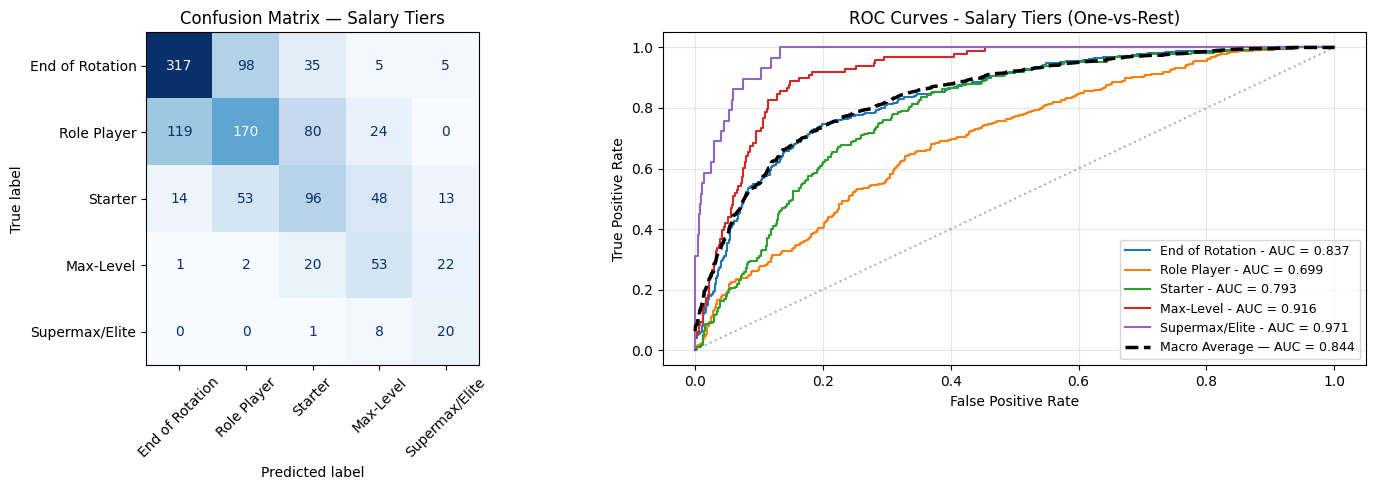

In [12]:
from sklearn.metrics import (
    confusion_matrix, roc_curve, roc_auc_score, f1_score, accuracy_score,
    ConfusionMatrixDisplay, auc as auc_score,
)
from sklearn.preprocessing import label_binarize

# Predictions on test set
y_pred = best_lr.predict(X_test_scaled)
y_proba = best_lr.predict_proba(X_test_scaled)  # shape: (n_samples, 5)

# Scalar metrics
accuracy = accuracy_score(y_test, y_pred)
f1_macro = f1_score(y_test, y_pred, average='macro')
auc_macro = roc_auc_score(y_test, y_proba, multi_class='ovr', average='macro')

print(f"=== Logistic Regression — Salary Tier Multiclass ===")
print(f"Accuracy:           {accuracy:.4f}")
print(f"Macro F1:           {f1_macro:.4f}")
print(f"Macro AUC (OvR):    {auc_macro:.4f}")

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
print(f"\nConfusion Matrix (rows=truth, cols=prediction):")
print(cm)

# Per-class ROC curves (one-vs-rest)
classes = sorted(y_test.unique())
class_labels = ['End of Rotation', 'Role Player', 'Starter', 'Max-Level', 'Supermax/Elite']
y_test_bin = label_binarize(y_test, classes=classes)

fpr_dict, tpr_dict, auc_dict = {}, {}, {}
for i, c in enumerate(classes):
    fpr_dict[c], tpr_dict[c], _ = roc_curve(y_test_bin[:, i], y_proba[:, i])
    auc_dict[c] = auc_score(fpr_dict[c], tpr_dict[c])

# Macro-average ROC curve
all_fpr = np.unique(np.concatenate([fpr_dict[c] for c in classes]))
mean_tpr = np.zeros_like(all_fpr)
for c in classes:
    mean_tpr += np.interp(all_fpr, fpr_dict[c], tpr_dict[c])
mean_tpr /= len(classes)
macro_auc = auc_score(all_fpr, mean_tpr)

# Plot confusion matrix + 6-curve ROC side by side
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_labels)
disp.plot(ax=axes[0], cmap='Blues', colorbar=False, xticks_rotation=45)
axes[0].set_title('Confusion Matrix — Salary Tiers')

colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
for i, c in enumerate(classes):
    axes[1].plot(fpr_dict[c], tpr_dict[c], color=colors[i], linewidth=1.5,
                 label=f'{class_labels[i]} - AUC = {auc_dict[c]:.3f}')
axes[1].plot(all_fpr, mean_tpr, color='black', linestyle='--', linewidth=2.5,
             label=f'Macro Average — AUC = {macro_auc:.3f}')
axes[1].plot([0, 1], [0, 1], 'k:', alpha=0.3)
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curves - Salary Tiers (One-vs-Rest)')
axes[1].legend(loc='lower right', fontsize=9)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Logistic Regression Results Summary

The Logistic Regression model trained on the five-class salary tier problem achieved **54.5% accuracy**, a **macro F1 score of 0.498**, and a **macro AUC of 0.843** on the held-out test set. While accuracy of ~55% may appear low compared to the binary classification results in Task 1, this is expected: five-class classification is fundamentally harder than two-class classification, and random chance is only 20%. The model is performing 2.7× better than chance, and the macro AUC of 0.843 indicates strong ranking quality--given two players from different salary tiers, the model correctly orders them by predicted tier 84.3% of the time.

The confusion matrix reveals two reassuring patterns. First, errors are concentrated along the diagonal: true minimum-tier players are misclassified almost entirely as role Players or starters, never as max-level or supermax players, and true supermax players are misclassified at worst as max-level. This adjacent-tier error structure means the model is making sensible mistakes rather than wild jumps across the salary distribution. Second, the bias direction is approximately symmetric--the model is just as likely to predict a higher tier than the true label as it is to predict a lower tier, suggesting that the tier cutoffs are well-calibrated to the underlying salary distribution rather than systematically biased.

The off-diagonal cells also represent the most analytically interesting players in the dataset: those whose on-court production substantially exceeds (or falls short of) what their salary tier would predict. These disagreements between stats-based prediction and actual salary tier form the basis of the cross-task analysis in Notebook 05--identifying the most underpaid and overpaid players in the league relative to their measurable production.

### Expanding to All Three Classifiers

Having validated our workflow using logistic regression, we can now  scale to random forest and gradient boost classifiers. Similar to binary classification, we define one resuable function that encompasses the training/tuning/evaluation logic.

The three classifiers use the same hyperparameter grids and 5-fold
cross-validation procedure described in detail in Notebook 02, Section 6a.
The full grids are:

- **Logistic Regression**: `C ∈ {0.001, 0.01, 0.1, 1, 10, 100}` (6 combinations)
- **Random Forest**: `n_estimators ∈ {200, 500}` × `max_depth ∈ {None, 10, 20}` (6 combinations)
- **Gradient Boosting**: `learning_rate ∈ {0.05, 0.1}` × `max_depth ∈ {None, 5, 10}` (6 combinations)

Macro F1 is the scoring metric for cross-validation in both notebooks, ensuring that hyperparameter selection optimizes for performance on the
minority classes rather than the majority class. The only methodological difference between Notebook 02 and Notebook 03 is the structure of the
target: binary for binary classification(four separate problems, one per cutoff), five-class multiclass in this notebook.

In [16]:
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

def tune_and_evaluate_multiclass(name, base_classifier, param_grid, needs_scaling):
    Xtr = X_train_scaled if needs_scaling else X_train.values
    Xte = X_test_scaled  if needs_scaling else X_test.values

    grid = GridSearchCV(
        estimator=base_classifier,
        param_grid=param_grid,
        cv=5,
        scoring='f1_macro',
        n_jobs=-1,
    )
    grid.fit(Xtr, y_train)
    best = grid.best_estimator_
    y_pred  = best.predict(Xte)
    y_proba = best.predict_proba(Xte)

    return {
        'classifier':       name,
        'best_params':      grid.best_params_,
        'cv_results':       pd.DataFrame(grid.cv_results_),
        'accuracy':         accuracy_score(y_test, y_pred),
        'f1_macro':         f1_score(y_test, y_pred, average='macro'),
        'auc_macro':        roc_auc_score(y_test, y_proba, multi_class='ovr', average='macro'),
        'confusion_matrix': confusion_matrix(y_test, y_pred),
        'y_pred':           y_pred,
        'y_proba':          y_proba,
        'fitted_model':     best,
    }

classifiers = [
    {
        'name': 'Logistic Regression',
        'classifier': LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42),
        'param_grid': {'C': [0.001, 0.01, 0.1, 1, 10, 100]},
        'needs_scaling': True,
    },
    {
        'name': 'Random Forest',
        'classifier': RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1),
        'param_grid': {'n_estimators': [200, 500], 'max_depth': [None, 10, 20]},
        'needs_scaling': False,
    },
    {
        'name': 'Gradient Boosting',
        'classifier': HistGradientBoostingClassifier(class_weight='balanced', random_state=42),
        'param_grid': {'learning_rate': [0.05, 0.1], 'max_depth': [None, 5, 10]},
        'needs_scaling': False,
    },
]

multiclass_results = []
for cfg in classifiers:
    print(f"Training {cfg['name']:20s}...", end=' ', flush=True)
    result = tune_and_evaluate_multiclass(
        name=cfg['name'],
        base_classifier=cfg['classifier'],
        param_grid=cfg['param_grid'],
        needs_scaling=cfg['needs_scaling'],
    )
    multiclass_results.append(result)
    print(f"Acc={result['accuracy']:.3f}  F1={result['f1_macro']:.3f}  "
          f"AUC={result['auc_macro']:.3f}  Best={result['best_params']}")

Training Logistic Regression ... Acc=0.545  F1=0.498  AUC=0.843  Best={'C': 1}
Training Random Forest       ... Acc=0.624  F1=0.585  AUC=0.891  Best={'max_depth': 10, 'n_estimators': 500}
Training Gradient Boosting   ... Acc=0.631  F1=0.598  AUC=0.892  Best={'learning_rate': 0.05, 'max_depth': None}




For each of the three classifiers, we generate the full multiclass evaluation visualized here: the 5×5 confusion matrix and the six-curve ROC plot (one curve per salary tier, plus the macro average). Presenting each classifier in its own figure keeps the ROC plot readable.

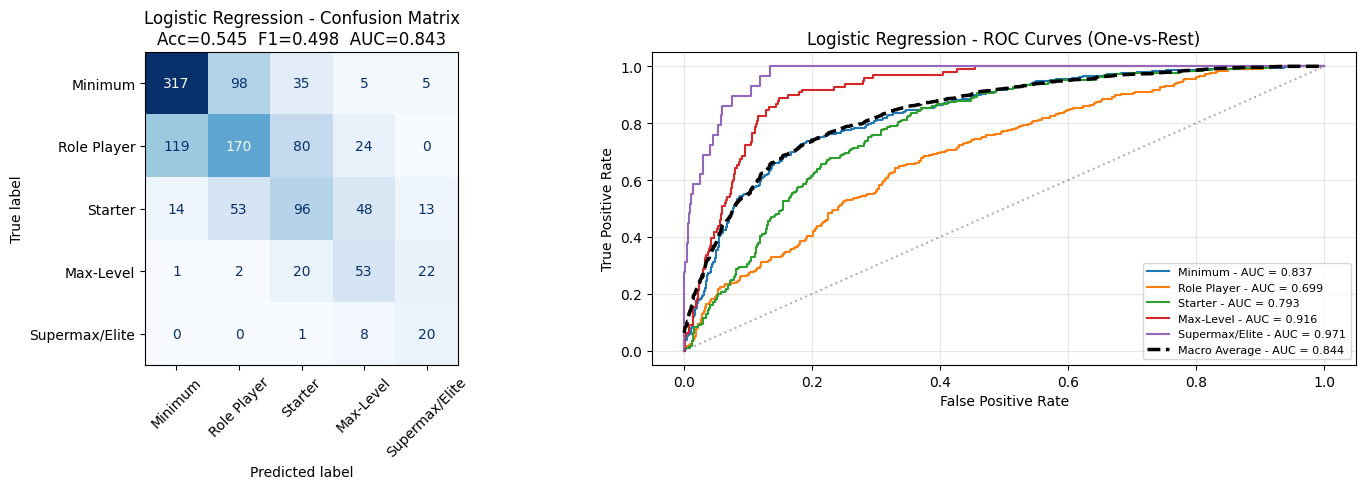

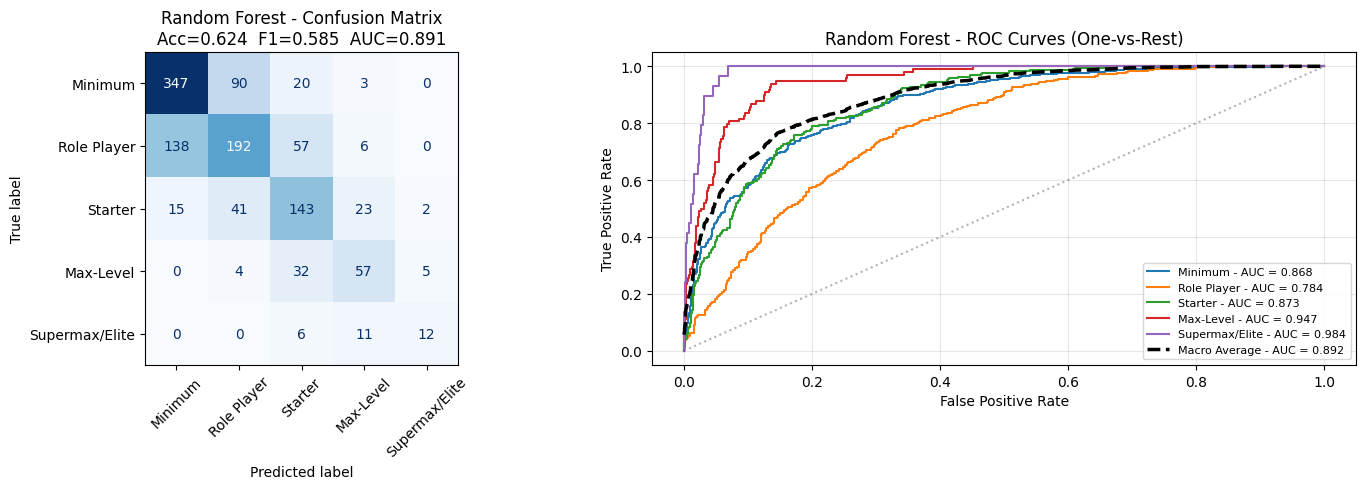

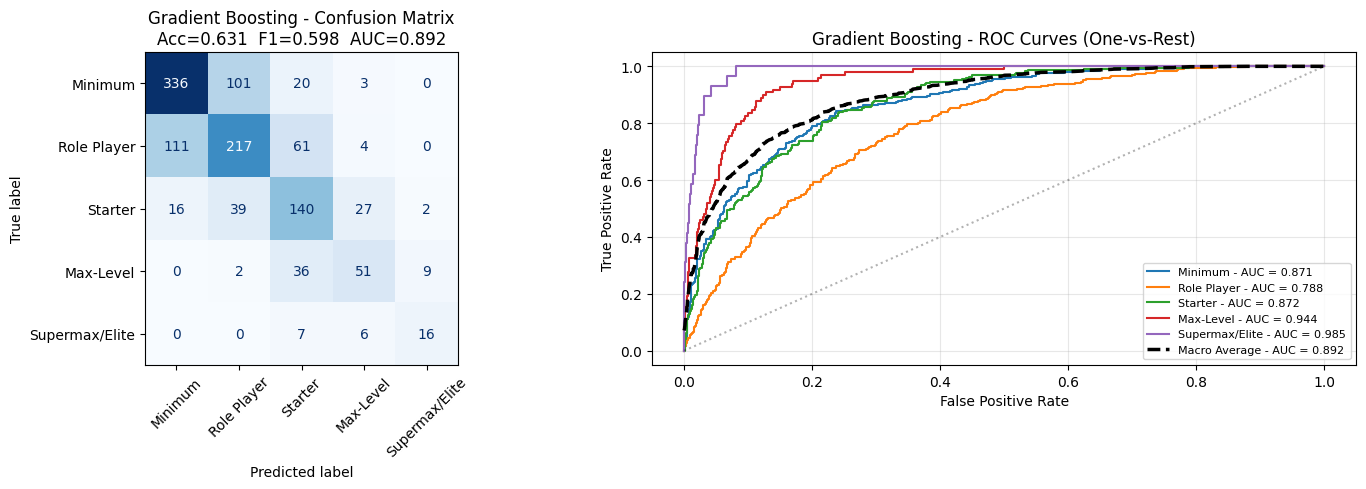

In [15]:
from sklearn.metrics import auc as auc_score
from sklearn.preprocessing import label_binarize

classes = sorted(y_test.unique())
class_labels = ['Minimum', 'Role Player', 'Starter', 'Max-Level', 'Supermax/Elite']
y_test_bin = label_binarize(y_test, classes=classes)
roc_colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']

def plot_multiclass_evaluation(result):
    """Generate confusion matrix + six-curve ROC for one classifier."""
    y_proba = result['y_proba']
    cm = result['confusion_matrix']

    # Compute per-class and macro-average ROC
    fpr_dict, tpr_dict, auc_dict = {}, {}, {}
    for i, c in enumerate(classes):
        fpr_dict[c], tpr_dict[c], _ = roc_curve(y_test_bin[:, i], y_proba[:, i])
        auc_dict[c] = auc_score(fpr_dict[c], tpr_dict[c])
    all_fpr = np.unique(np.concatenate([fpr_dict[c] for c in classes]))
    mean_tpr = np.zeros_like(all_fpr)
    for c in classes:
        mean_tpr += np.interp(all_fpr, fpr_dict[c], tpr_dict[c])
    mean_tpr /= len(classes)
    macro_auc = auc_score(all_fpr, mean_tpr)

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # 5x5 confusion matrix
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_labels)
    disp.plot(ax=axes[0], cmap='Blues', colorbar=False, xticks_rotation=45)
    axes[0].set_title(f"{result['classifier']} - Confusion Matrix\n"
                      f"Acc={result['accuracy']:.3f}  "
                      f"F1={result['f1_macro']:.3f}  "
                      f"AUC={result['auc_macro']:.3f}")

    # Six-curve ROC plot
    for i, c in enumerate(classes):
        axes[1].plot(fpr_dict[c], tpr_dict[c], color=roc_colors[i], linewidth=1.5,
                     label=f'{class_labels[i]} - AUC = {auc_dict[c]:.3f}')
    axes[1].plot(all_fpr, mean_tpr, color='black', linestyle='--', linewidth=2.5,
                 label=f'Macro Average - AUC = {macro_auc:.3f}')
    axes[1].plot([0, 1], [0, 1], 'k:', alpha=0.3)
    axes[1].set_xlabel('False Positive Rate')
    axes[1].set_ylabel('True Positive Rate')
    axes[1].set_title(f"{result['classifier']} - ROC Curves (One-vs-Rest)")
    axes[1].legend(loc='lower right', fontsize=8)
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

for r in multiclass_results:
    plot_multiclass_evaluation(r)

### Comprehensive Results Summary — Multiclass Salary Tier Classification

Across all three classifiers, the multiclass salary tier classification produced consistent, interpretable, and analytically meaningful results. Logistic Regression achieved 54.5% accuracy, 0.498 macro F1, and 0.843 macro AUC; Random Forest reached 62.4% accuracy, 0.585 macro F1, and 0.891 macro AUC; and Gradient Boosting marginally edged Random Forest at 63.1% accuracy, 0.598 macro F1, and 0.892 macro AUC. Although raw accuracy in the 54%-63% range may appear modest at first glance, this performance is strong in the context of a five-class problem where random chance is only 20%--even the weakest classifier (Logistic Regression) outperforms chance by nearly a factor of three, and the tree-based methods do so by more than a factor of three.

The 9-percentage-point performance gap between Logistic Regression and the tree-based methods is notably larger than the corresponding gap observed in Task 1's binary classification. This indicates that predicting salary tier depends more heavily on non-linear feature interactions than predicting BPM tier did: a player's pay reflects not just raw production volume but the specific combinations of skills and demographics that the market values (e.g., a young, high-usage scorer is paid differently than an older, low-usage defender even if their BPM is similar). Random Forest and Gradient Boosting, which natively capture these interactions through their tree-based structure, substantially outperform Logistic Regression's single linear decision boundary as a result. The fact that both tree-based methods land within 0.01 of each other on every metric also indicates that they have likely captured close to the predictive ceiling achievable from the available features.

The confusion matrices for all three classifiers show the same encouraging structural pattern: errors cluster along the diagonal, with true Minimum-tier players almost never misclassified as Max-Level or Supermax players, and true Supermax players misclassified at worst as Max-Level. This adjacent-tier error structure means the models are making sensible, calibrated mistakes rather than wild jumps across the salary distribution — they correctly identify which neighborhood of pay a player belongs to even when they don't always pin the exact tier. Off-diagonal errors are also roughly symmetric: the models are not systematically biased toward predicting higher or lower tiers than the truth, indicating that the percentile-based cutoffs are well-calibrated to the underlying salary distribution.

The six-curve ROC plots reveal which salary tiers are easiest and hardest to identify. Across all three classifiers, the Minimum tier (class 1) and Supermax/Elite tier (class 5) achieve the highest one-vs-rest AUC values, typically above 0.93. This is expected: these extreme tiers are the most distinct from the rest of the salary distribution. Players on minimum-or-near-minimum contracts have meaningfully different on-court profiles from rotation regulars (less volume, less efficiency, less playmaking), and Supermax-level players have similarly distinctive profiles (high volume combined with high efficiency and broad statistical contribution). The middle tiers (Role Player, Starter, Max-Level) achieve lower one-vs-rest AUCs in the 0.78-0.85 range, reflecting the genuine ambiguity at boundaries between adjacent tiers--a $14 million player and a $16 million player are not always statistically distinguishable. The macro-average AUC, sitting between these extremes, summarizes overall discriminatory ability across all five class boundaries.

Taken together, these results have two implications for the project's analytical extensions. First, the strong macro AUC values (0.84-0.89) confirm that on-court box-score statistics are highly informative about salary--they encode the bulk of the signal that determines NBA pay. Second, the substantial off-diagonal mass in the confusion matrices--players whose stats-based prediction differs from their actual salary tier--represents the population of "mismatched" players whose market value diverges from their statistical value.